# Week 7 · Task B — The static spine: four charts, four questions
Reads only `clean/` (written by `partA_process.ipynb`). Four different question types from Week 1's table:

| # | Question type | Chart | Data | Decision it supports |
|---|---|---|---|---|
| 1 | **Trend** (time axis) | daily boardings by mode, 7-day mean, line breaks at unfiled days | `ridership_daily` | where capacity is moving |
| 2 | **Composition** (part-to-whole) | 100 % stacked bars of fare **revenue** share by mode | `fare_revenue` | which mode the fare box depends on |
| 3 | **Comparison on a map** | boardings per 1,000 residents, equal-area, Jenks breaks | register | where the next corridor goes |
| 4 | **Relationship** | crowding vs punctuality, per route | `routes` | whether adding vehicles fixes lateness |

Every figure: finding in the title, decision in the caption, zero baseline on bars, no second y-axis, direct labels, parameters and exclusions declared on the figure, 300 dpi, source note.

In [1]:
import sys, os
from pathlib import Path
def _find_root():
    here = Path.cwd()
    for p in [here, here / "week7" / "assignments", here.parent / "assignments"]:
        if (p / "dashlib.py").exists() and (p / "data" / "ridership_daily.csv").exists():
            return p
    raise FileNotFoundError("Put this notebook in week7/assignments/ (next to dashlib.py) and run it from there.")
ROOT = _find_root(); os.chdir(ROOT); sys.path.insert(0, str(ROOT))
print("working in", ROOT)

working in c:\Users\Nas Graphy\Downloads\Data-Visualization\Week 7


In [2]:
import numpy as np, pandas as pd, textwrap
import matplotlib; import matplotlib.pyplot as plt
import vizlib, tslib, geolib, dashlib
from vizlib import PALETTE
vizlib.style_defaults()
pd.set_option("display.width", 200)
CLEAN = Path("clean")
need = ["district_transit_clean.csv", "routes_clean.csv", "ridership_calendar.csv", "fare_revenue_clean.csv"]
assert all((CLEAN / f).exists() for f in need), "Run partA_process.ipynb first: it writes clean/"

reg = pd.read_csv(CLEAN / "district_transit_clean.csv")
rt = pd.read_csv(CLEAN / "routes_clean.csv")
cal = pd.read_csv(CLEAN / "ridership_calendar.csv", parse_dates=["date"])
fr = pd.read_csv(CLEAN / "fare_revenue_clean.csv")
feats = geolib.read_geojson("data/regions.geojson")
parts = fr[~fr.is_total]                                  # the 216 real parts; the 72 subtotals are out
COMPLETE_END = "2026-08-31"                               # 2026-09 is a partial month (Bus, Ferry stopped filing 22 Sep)
MODES = ["Metro", "BRT", "Bus", "Ferry"]
# one hue per mode, everywhere. Ferry's 4th hue is below 3:1 contrast on white, so every mode is ALSO direct-labelled.
MODE_COL = {"Metro": PALETTE["series"][0], "BRT": PALETTE["series"][2], "Bus": PALETTE["series"][1], "Ferry": PALETTE["series_4th"]}
filed = cal[cal.status == "filed"]

def wrap(s, n=160): return "\n".join(textwrap.wrap(s, n))
def frame(fig, title, caption, top=0.84):
    """Finding as the title, the decision it supports as a one-line caption."""
    fig.text(0.01, 0.995, title, ha="left", va="top", fontsize=13.5, fontweight="bold", color=PALETTE["ink"])
    fig.text(0.01, 0.995 - 0.075 * (6.0 / fig.get_size_inches()[1]), caption, ha="left", va="top", fontsize=9.5, style="italic", color=PALETTE["ink_soft"])
    fig.subplots_adjust(top=top)

## Chart 1 · Trend — boardings per day by mode

mean boardings per FILED day, Apr 2025 -> Aug 2026 (complete months):
 mode          BRT       Bus    Ferry      Metro
mo                                             
2025-04  559089.0  847124.0  53258.0   646666.0
2026-08  585875.0  499078.0  39460.0  1248784.0
change %: {'BRT': 4.8, 'Bus': -41.1, 'Ferry': -25.9, 'Metro': 93.1}


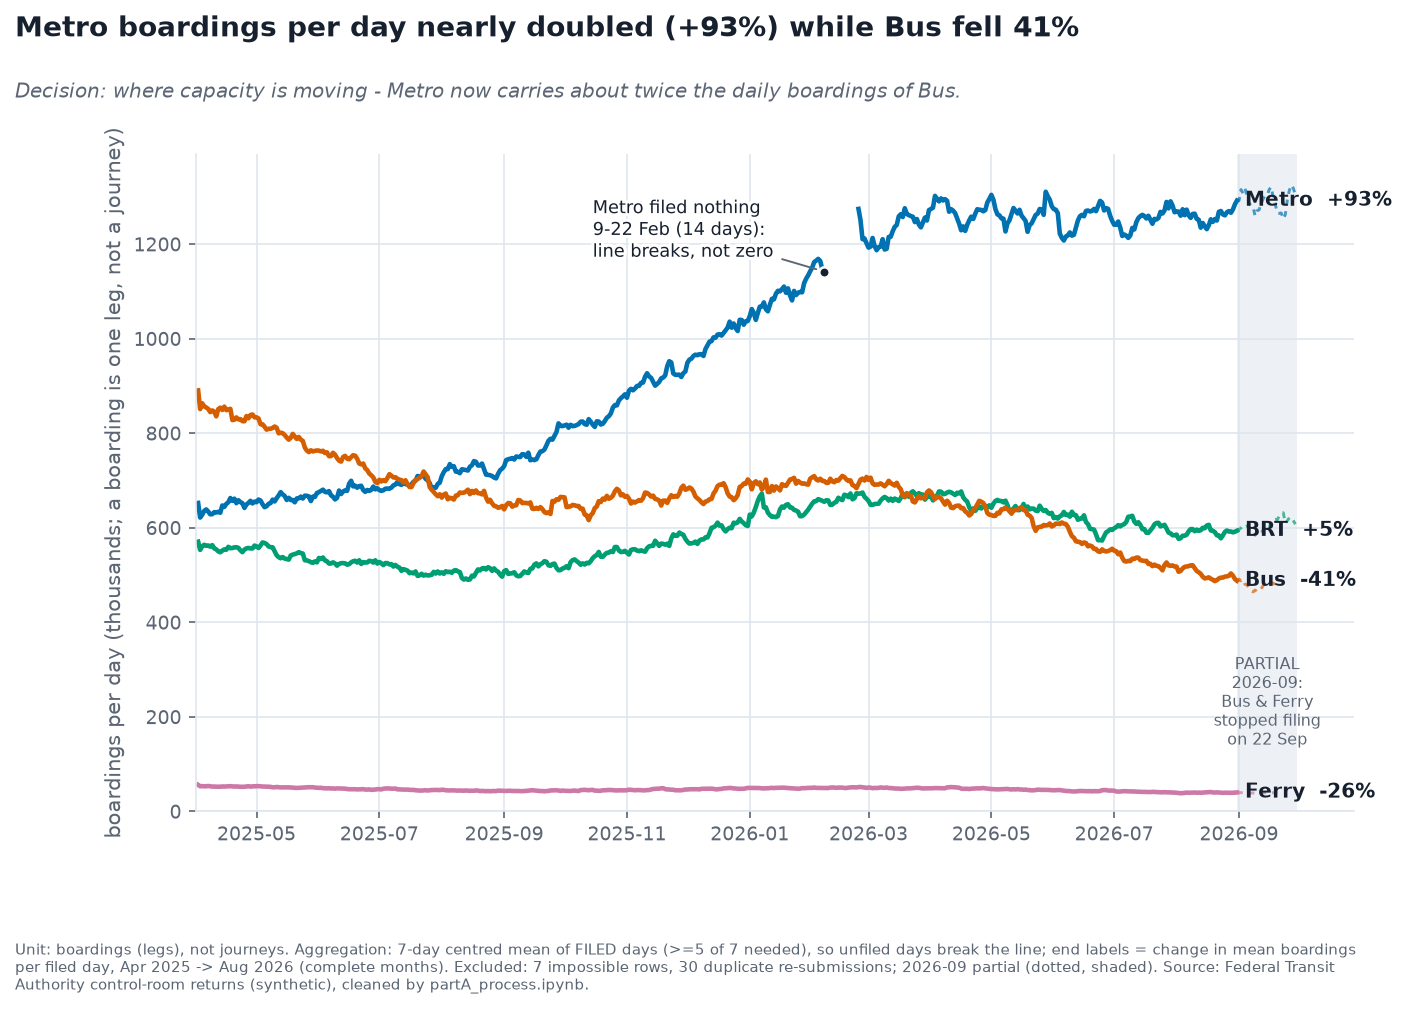

In [3]:
wide = cal.pivot(index="date", columns="mode", values="boardings")[MODES]          # NaN = nobody filed (or withheld)
sm = wide.rolling(7, center=True, min_periods=5).mean()                              # needs >=5 filed days of 7 -> a hole breaks the line
# the 14-day Metro hole must still be a hole after smoothing
assert sm.loc["2026-02-12":"2026-02-19", "Metro"].isna().all()
m = filed[(filed.date <= COMPLETE_END)].assign(mo=lambda d: d.date.dt.to_period("M")).groupby(["mo", "mode"]).boardings.mean().unstack()
chg = (m.iloc[-1] / m.iloc[0] - 1) * 100
print("mean boardings per FILED day, Apr 2025 -> Aug 2026 (complete months):\n", m.iloc[[0, -1]].round(0).to_string())
print("change %:", chg.round(1).to_dict())

fig, ax = plt.subplots(figsize=(10.5, 6.0))
end = pd.Timestamp(COMPLETE_END)
for mo in MODES:
    s = sm[mo] / 1000
    ax.plot(s[s.index <= end].index, s[s.index <= end], color=MODE_COL[mo], lw=2.2)
    p = s[s.index >= end]; ax.plot(p.index, p, color=MODE_COL[mo], lw=1.4, ls=(0, (2, 2)), alpha=0.7)    # partial period: dotted, lighter
    last = s[s.index <= end].dropna().iloc[-1]
    ax.text(end + pd.Timedelta(days=4), last, f"{mo}  {chg[mo]:+.0f}%", color=PALETTE["ink"], fontsize=9.5, va="center", fontweight="bold")
ax.axvspan(end, wide.index.max(), color=PALETTE["grid"], alpha=0.55, lw=0)
ax.text(end + pd.Timedelta(days=15), 330, "PARTIAL\n2026-09:\nBus & Ferry\nstopped filing\non 22 Sep", fontsize=7.5, color=PALETTE["ink_soft"], va="top", ha="center")
gap_x = sm.loc[:"2026-02-08", "Metro"].dropna().index[-1]; dashlib.callout(ax, (gap_x, sm.loc[gap_x, "Metro"] / 1000), "Metro filed nothing\n9-22 Feb (14 days):\nline breaks, not zero", xytext=(pd.Timestamp("2025-10-15"), 1230), fontsize=8.5)
ax.set_ylim(0, None); ax.set_xlim(wide.index.min(), wide.index.max() + pd.Timedelta(days=28))
ax.set_ylabel("boardings per day (thousands; a boarding is one leg, not a journey)")
frame(fig, f"Metro boardings per day nearly doubled ({chg['Metro']:+.0f}%) while Bus fell {abs(chg['Bus']):.0f}%",
      "Decision: where capacity is moving - Metro now carries about twice the daily boardings of Bus.")
fig.subplots_adjust(right=0.86)
p1 = vizlib.save_fig(fig, "partB_1.png", note=wrap(
    "Unit: boardings (legs), not journeys. Aggregation: 7-day centred mean of FILED days (>=5 of 7 needed), so unfiled days break the line; end labels = change in mean boardings per filed day, Apr 2025 -> Aug 2026 (complete months). "
    "Excluded: 7 impossible rows, 30 duplicate re-submissions; 2026-09 partial (dotted, shaded). Source: Federal Transit Authority control-room returns (synthetic), cleaned by partA_process.ipynb.", 175))
plt.show()

## Chart 2 · Composition — who pays the fare box?
The parts are made mutually exclusive first (the 72 `All tickets` subtotals are out), and I assert the shares sum to 100 %. **Revenue** is drawn, not journeys: the finance director quotes money, and the two differ (a Metro journey earns 48.3 PKR, a bus journey 26.1).

2025-04 -> 2026-08: journeys +12.1%, revenue +26.9%
Aug-2026 journey share: {'Metro': 49.4, 'BRT': 24.9, 'Bus': 23.5, 'Ferry': 2.2}
Aug-2026 revenue share: {'Metro': 58.8, 'BRT': 22.9, 'Bus': 14.8, 'Ferry': 3.4}
PKR per journey Aug-2026: {'Metro': 49.2, 'BRT': 38.0, 'Bus': 26.1, 'Ferry': 65.8}


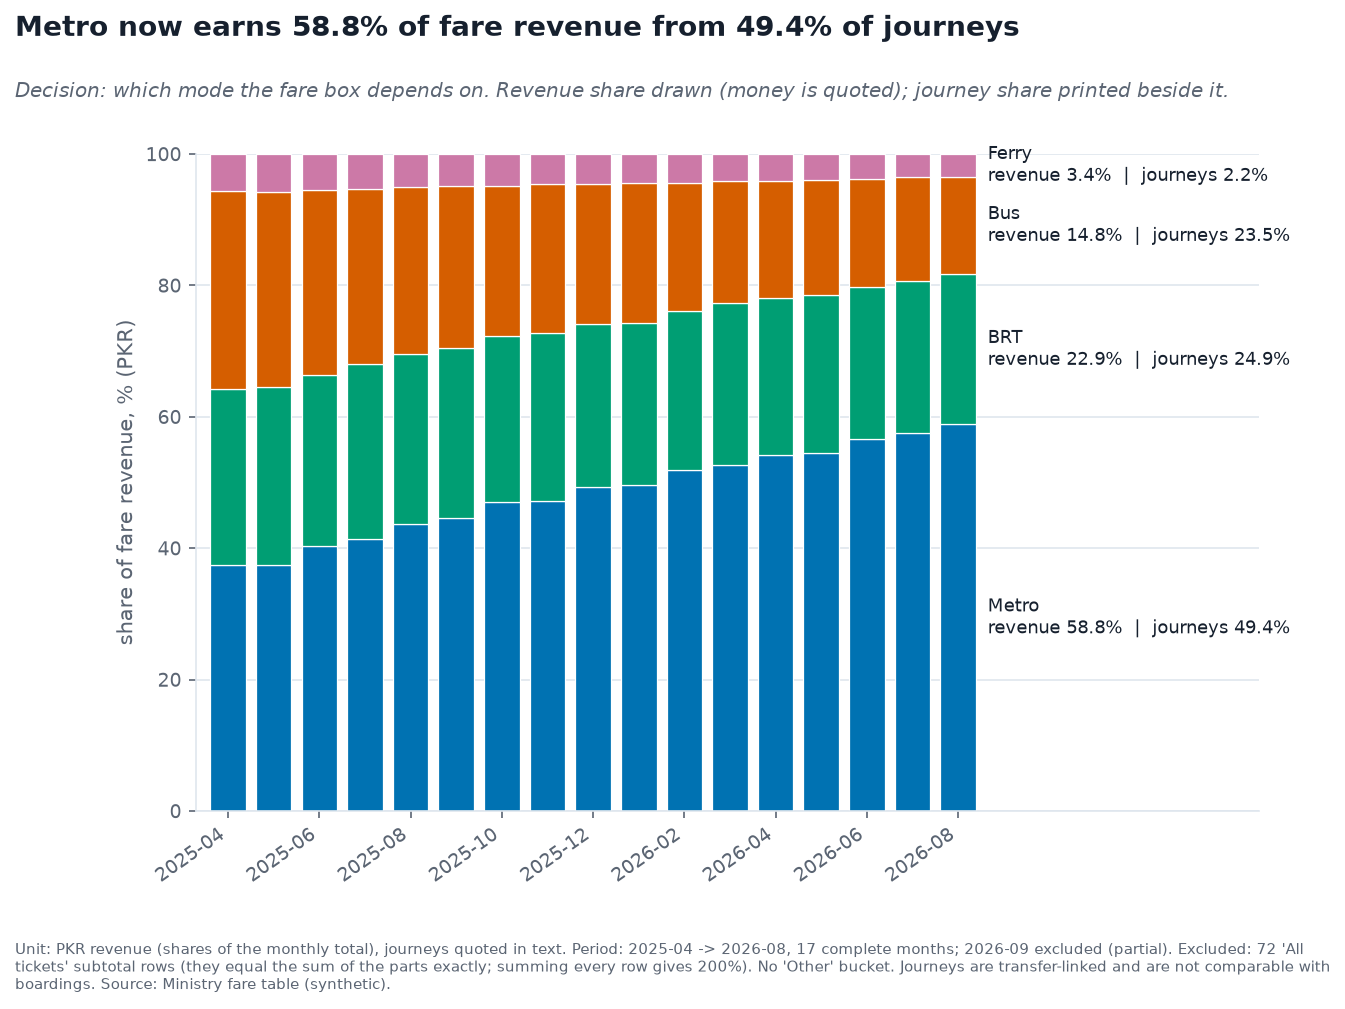

In [4]:
pm = parts[parts.complete_month].groupby(["month", "mode"])[["trips", "revenue_pkr"]].sum()
rev = pm.revenue_pkr.unstack()[MODES]; jn = pm.trips.unstack()[MODES]
rs, js = rev.div(rev.sum(axis=1), axis=0) * 100, jn.div(jn.sum(axis=1), axis=0) * 100
assert np.allclose(rs.sum(axis=1), 100) and np.allclose(js.sum(axis=1), 100)          # exclusive parts -> 100 %
first, last_ = rs.index[0], rs.index[-1]
ppj = rev.iloc[-1] / jn.iloc[-1]
print(f"{first} -> {last_}: journeys {(jn.iloc[-1].sum()/jn.iloc[0].sum()-1)*100:+.1f}%, revenue {(rev.iloc[-1].sum()/rev.iloc[0].sum()-1)*100:+.1f}%")
print("Aug-2026 journey share:", js.iloc[-1].round(1).to_dict()); print("Aug-2026 revenue share:", rs.iloc[-1].round(1).to_dict())
print("PKR per journey Aug-2026:", ppj.round(1).to_dict())

fig, ax = plt.subplots(figsize=(10.5, 6.0)); x = np.arange(len(rs)); bottom = np.zeros(len(rs))
for mo in MODES:
    ax.bar(x, rs[mo], bottom=bottom, color=MODE_COL[mo], width=0.78, edgecolor="white", lw=0.6); bottom += rs[mo].values
cum = 0
for mo in MODES:
    v = rs[mo].iloc[-1]; ax.text(len(rs) - 0.35, cum + v / 2, f"{mo}\nrevenue {v:.1f}%  |  journeys {js[mo].iloc[-1]:.1f}%", va="center", fontsize=8.6, color=PALETTE["ink"]); cum += v
ax.set_xticks(x[::2]); ax.set_xticklabels(rs.index[::2], rotation=35, ha="right"); ax.set_ylim(0, 100); ax.set_xlim(-0.7, len(rs) + 5.6)
ax.set_ylabel("share of fare revenue, % (PKR)"); ax.grid(axis="x", visible=False)
frame(fig, f"Metro now earns {rs['Metro'].iloc[-1]:.1f}% of fare revenue from {js['Metro'].iloc[-1]:.1f}% of journeys",
      "Decision: which mode the fare box depends on. Revenue share drawn (money is quoted); journey share printed beside it.")
fig.subplots_adjust(right=0.80)
p2 = vizlib.save_fig(fig, "partB_2.png", note=wrap(
    "Unit: PKR revenue (shares of the monthly total), journeys quoted in text. Period: 2025-04 -> 2026-08, 17 complete months; 2026-09 excluded (partial). Excluded: 72 'All tickets' subtotal rows (they equal the sum of the parts exactly; summing every row gives 200%). "
    "No 'Other' bucket. Journeys are transfer-linked and are not comparable with boardings. Source: Ministry fare table (synthetic).", 175))
plt.show()

## Chart 3 · The map — boardings per 1,000 residents
Normalized (a count map of boardings is a population map: r = +0.945, see Task E), **equal-area** projection, Jenks natural breaks with the edges printed, one-hue lightness ramp.

Jenks breaks (boardings per 1,000 residents): [4683, 8090, 11921, 16179, 20437, 30655] | GVF: 0.966
top 3 by rate: {'D12': 30655.0, 'D21': 28101.0, 'D09': 25546.0}


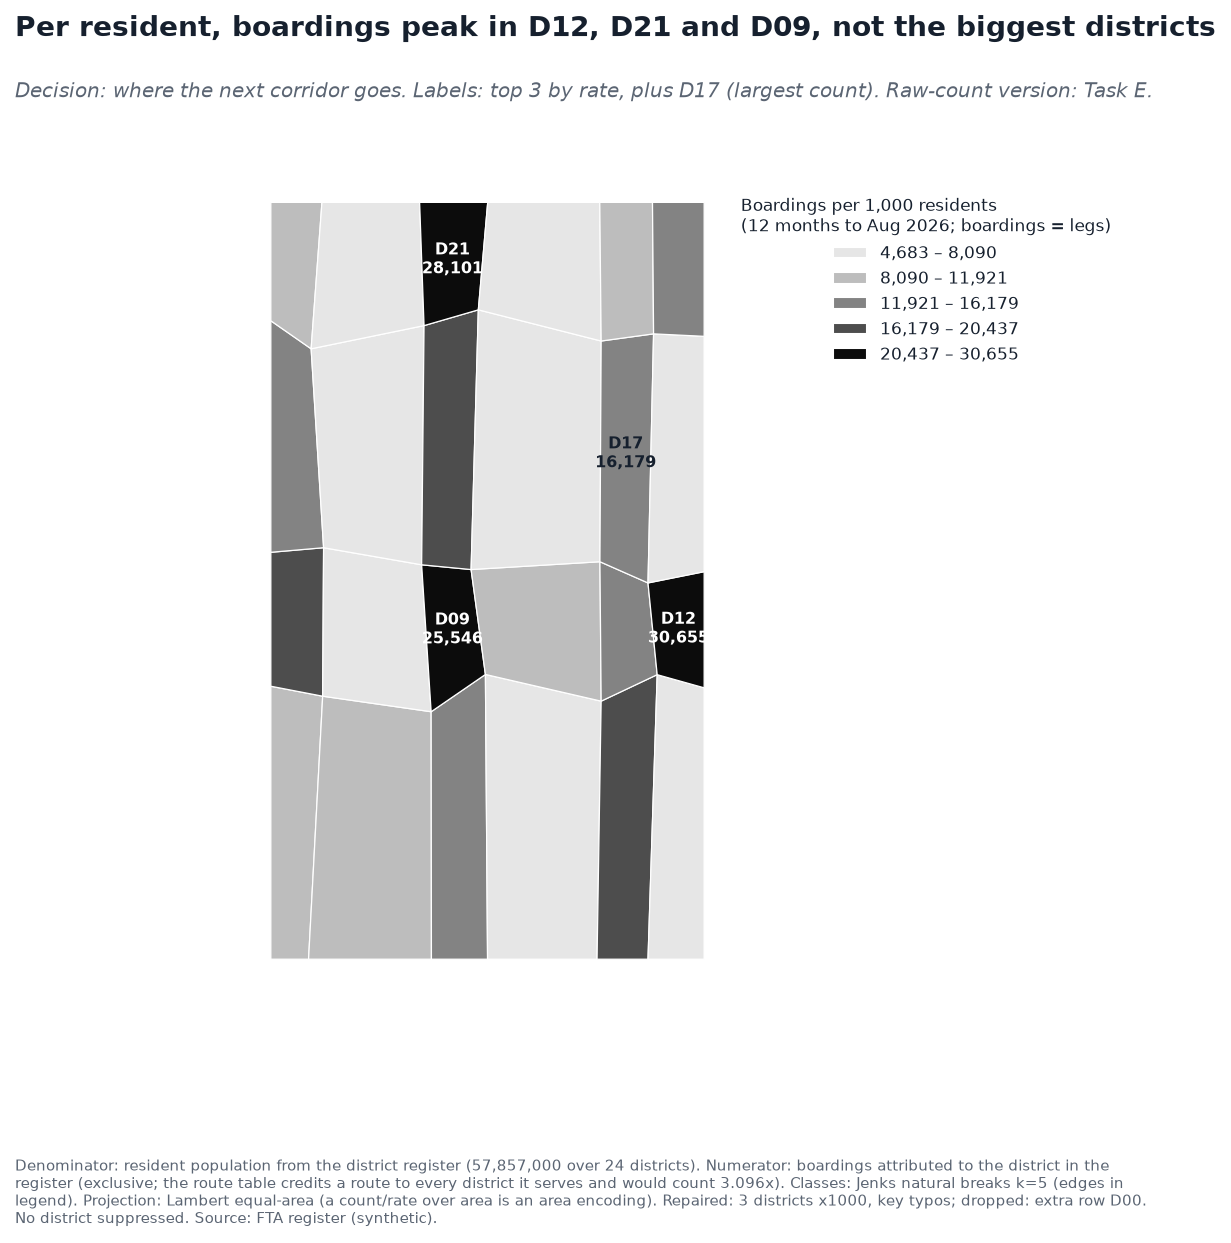

In [5]:
rate = (reg.set_index("code").boardings_annual / reg.set_index("code").population * 1000)
edges = geolib.breaks(rate.loc[[f["code"] for f in feats]].values, "natural", 5)
print("Jenks breaks (boardings per 1,000 residents):", [round(e) for e in edges], "| GVF:", round(geolib.gvf(rate.values, edges), 3))
top3 = rate.sort_values(ascending=False).head(3); print("top 3 by rate:", top3.round(0).to_dict())

fig, ax = plt.subplots(figsize=(10.5, 7.4))
edges = geolib.choropleth(ax, feats, rate.to_dict(), scheme="natural", k=5, cmap="Greys", projection="equal_area", edgecolor="white", lw=0.6,
                          legend_title="Boardings per 1,000 residents\n(12 months to Aug 2026; boardings = legs)", legend_loc="upper left", legend_anchor=(1.0, 0.98))
lat_ts = geolib._collection_lat_ts(feats)
for f in feats:
    if f["code"] in list(top3.index) + ["D17"]:
        lon, lat = geolib.representative_point(f["ring"]); px, py = geolib.equal_area_xy([lon], [lat], lat_ts=lat_ts)
        dark = f["code"] in top3.index or rate[f["code"]] > edges[3]
        ax.annotate(f"{f['code']}\n{rate[f['code']]:,.0f}", (px[0], py[0]), fontsize=7.5, ha="center", va="center", color="white" if dark else PALETTE["ink"], fontweight="bold")
frame(fig, f"Per resident, boardings peak in {top3.index[0]}, {top3.index[1]} and {top3.index[2]}, not the biggest districts",
      "Decision: where the next corridor goes. Labels: top 3 by rate, plus D17 (largest count). Raw-count version: Task E.", top=0.86)
fig.subplots_adjust(left=0.02, right=0.60)
p3 = vizlib.save_fig(fig, "partB_3.png", note=wrap(
    "Denominator: resident population from the district register (57,857,000 over 24 districts). Numerator: boardings attributed to the district in the register (exclusive; the route table credits a route to every district it serves and would count 3.096x). "
    "Classes: Jenks natural breaks k=5 (edges in legend). Projection: Lambert equal-area (a count/rate over area is an area encoding). Repaired: 3 districts x1000, key typos; dropped: extra row D00. No district suppressed. Source: FTA register (synthetic).", 150))
plt.show()

## Chart 4 · Relationship — does crowding explain lateness?

n=33 routes, excluded (999 code): ['R003', 'R025', 'R033']; r(all)=+0.41; r(Bus only)=+0.10
        n  crowd  ontime
mode                    
Metro   3   1.04   92.27
BRT     6   1.17   87.47
Bus    21   0.89   70.21
Ferry   3   0.74   80.07


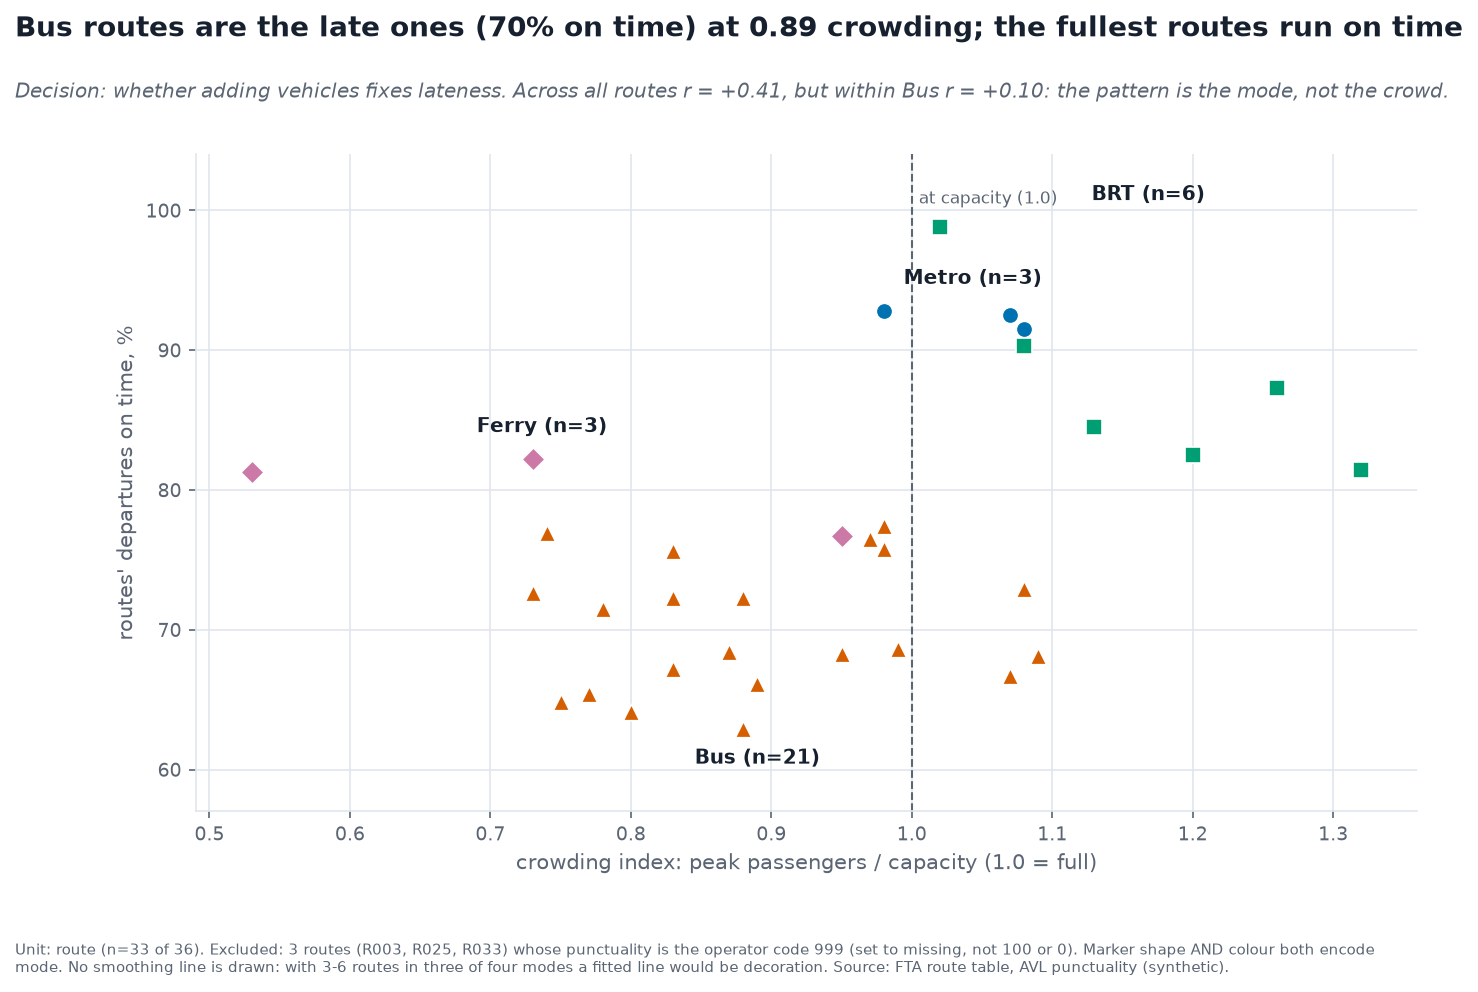

In [6]:
r4 = rt.dropna(subset=["punctuality_pct"]).copy()
excluded = rt[rt.punctuality_pct.isna()].route_id.tolist()
r_all = r4[["crowding_index", "punctuality_pct"]].corr().iloc[0, 1]
mm = r4.groupby("mode").agg(n=("route_id", "size"), crowd=("crowding_index", "mean"), ontime=("punctuality_pct", "mean")).reindex(MODES)
r_bus = r4[r4["mode"] == "Bus"][["crowding_index", "punctuality_pct"]].corr().iloc[0, 1]
print(f"n={len(r4)} routes, excluded (999 code): {excluded}; r(all)={r_all:+.2f}; r(Bus only)={r_bus:+.2f}"); print(mm.round(2).to_string())

fig, ax = plt.subplots(figsize=(10.5, 6.0))
for mo, mk in zip(MODES, vizlib.MARKERS):
    g = r4[r4["mode"] == mo]
    ax.scatter(g.crowding_index, g.punctuality_pct, s=62, marker=mk, color=MODE_COL[mo], edgecolor="white", lw=0.8, zorder=4)
    below = mo == "Bus"
    ax.text(g.crowding_index.mean(), (g.punctuality_pct.min() - 1.4) if below else (g.punctuality_pct.max() + 1.6), f"{mo} (n={len(g)})", color=PALETTE["ink"], fontsize=9.5, fontweight="bold", ha="center", va="top" if below else "bottom")
ax.axvline(1.0, color=PALETTE["ink_soft"], lw=1, ls="--"); ax.text(1.005, 100.5, "at capacity (1.0)", fontsize=8, color=PALETTE["ink_soft"])
ax.set_xlabel("crowding index: peak passengers / capacity (1.0 = full)"); ax.set_ylabel("routes' departures on time, %"); ax.set_ylim(57, 104)
frame(fig, f"Bus routes are the late ones ({mm.loc['Bus','ontime']:.0f}% on time) at {mm.loc['Bus','crowd']:.2f} crowding; the fullest routes run on time",
      f"Decision: whether adding vehicles fixes lateness. Across all routes r = {r_all:+.2f}, but within Bus r = {r_bus:+.2f}: the pattern is the mode, not the crowd.")
p4 = vizlib.save_fig(fig, "partB_4.png", note=wrap(
    f"Unit: route (n={len(r4)} of 36). Excluded: {len(excluded)} routes ({', '.join(excluded)}) whose punctuality is the operator code 999 (set to missing, not 100 or 0). Marker shape AND colour both encode mode. "
    "No smoothing line is drawn: with 3-6 routes in three of four modes a fitted line would be decoration. Source: FTA route table, AVL punctuality (synthetic).", 175))
plt.show()

In [7]:
from PIL import Image
for p in ["partB_1.png", "partB_2.png", "partB_3.png", "partB_4.png"]:
    im = Image.open(p); print(p, im.size, "dpi", im.info.get("dpi"))

partB_1.png (2811, 2019) dpi (299.9994, 299.9994)
partB_2.png (2613, 2019) dpi (299.9994, 299.9994)
partB_3.png (2457, 2486) dpi (299.9994, 299.9994)
partB_4.png (2958, 1984) dpi (299.9994, 299.9994)
